# code_211 · Fairness objectives need denominators and outcome coverage

**Book:** section 40.1. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_40_GUIDE.md), [execution evidence](../CHAPTER_40_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_211).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evidence contracts identify the protected unit, group denominators, permitted access, threat assumptions and decision responsibility. All household identities and data are generated fixtures. Seeded privacy-noise simulations are reproducible utility demonstrations, not protected releases. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8011;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8011


## Audit the defined decision and the labels that make it visible
 Generate source2,400, development600 and final1,200 independent inspection candidates. The generated neighbourhood indicator is a teaching group, not a claim about a real population. Severity and age are visible. True finding probability logistic(-1+1.4severity+0.5age+0.8group) differs by group. Outcome observation is less likely for group1 and depends on the finding itself. Fit logistic regression without group using only observed source labels; omitting the group does not establish fairness. Independent development outcomes are assumed completely obtained by a separate audit. Compare common threshold0.5 with group-specific thresholds set to the twentieth percentile of each group's development-positive probabilities (approximately80% development TPR). These are deterministic quantile choices, not the complete equalized-odds randomized optimizer. Final outcomes do not choose thresholds. There is no imposed shared inspection capacity in this comparison; allocation volume must therefore be reported.


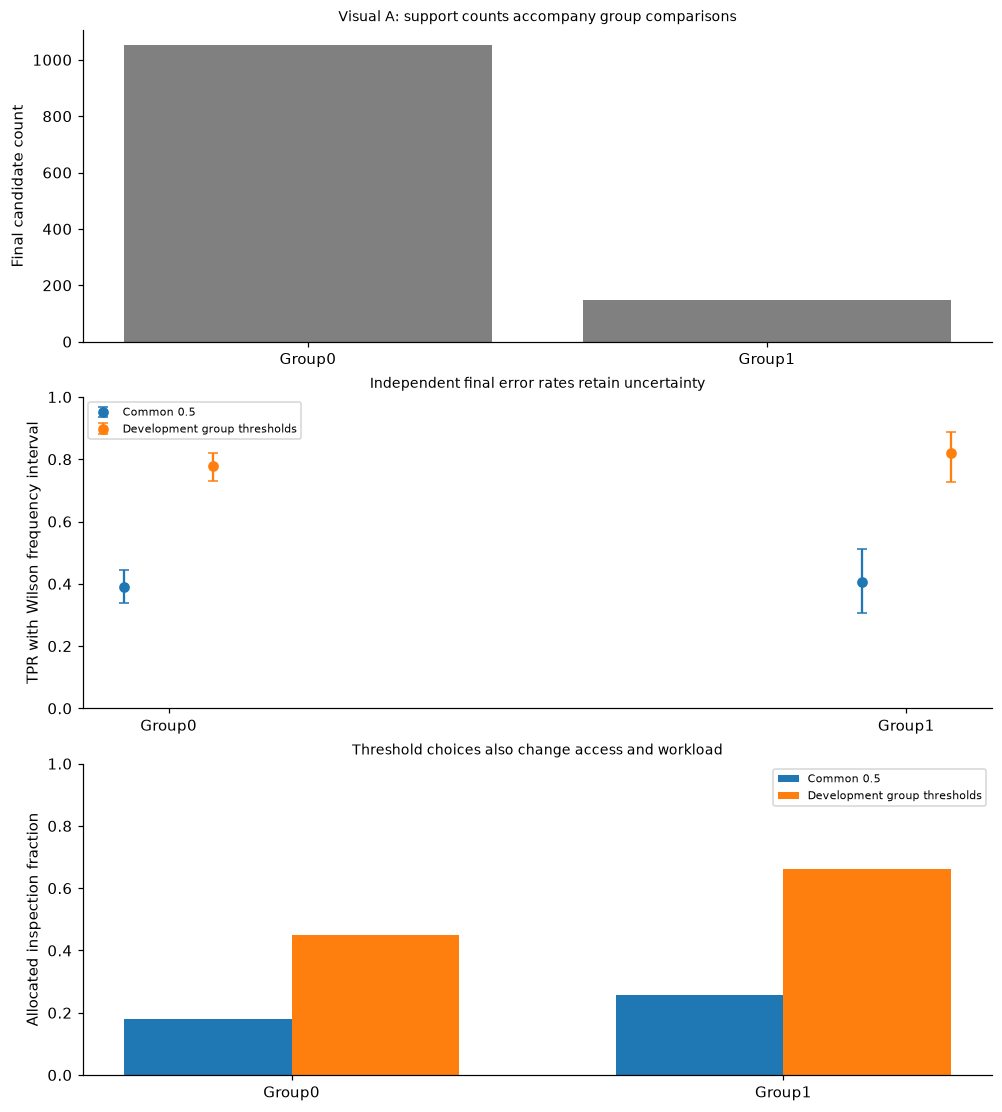

In [2]:
from sklearn.linear_model import LogisticRegression
def cohort(n,prevalence=.2):
    g=rng.binomial(1,prevalence,n);x=np.c_[rng.normal(.2*g,1,n),rng.uniform(-1,1,n)];y=rng.binomial(1,expit(-1+1.4*x[:,0]+.5*x[:,1]+.8*g));observation_probability=np.where(g==1,.25,.8)*np.where(y==1,.65,1.);observed=rng.random(n)<observation_probability;return x,g,y,observed
xs,gs,ys,obs=cohort(2400);xd,gd,yd,_=cohort(600);xf,gf,yf,seen=cohort(1200,.12);model=LogisticRegression(C=1,max_iter=300).fit(xs[obs],ys[obs]);pdv=model.predict_proba(xd)[:,1];pf=model.predict_proba(xf)[:,1];thresholds={g:float(np.quantile(pdv[(gd==g)&(yd==1)],.2)) for g in [0,1]};decisions={'Common 0.5':pf>=.5,'Development group thresholds':pf>=np.array([thresholds[int(g)] for g in gf])}
def wilson(k,n):
    if n==0:return [0.,1.]
    z=1.96;p=k/n;d=1+z*z/n;mid=(p+z*z/(2*n))/d;half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d;return [float(mid-half),float(mid+half)]
def audit(decision,mask):
    y=yf[mask];a=decision[mask];pos=int(y.sum());neg=len(y)-pos;tp=int(np.sum(a&(y==1)));fp=int(np.sum(a&(y==0)));return {'n':len(y),'positives':pos,'selected':int(a.sum()),'allocation_fraction':float(a.mean()),'TPR':tp/pos if pos else None,'TPR_Wilson95':wilson(tp,pos),'FPR':fp/neg if neg else None,'precision':tp/int(a.sum()) if a.sum() else None,'Brier':float(np.mean((pf[mask]-y)**2))}
audits={name:{str(g):audit(a,gf==g) for g in [0,1]} for name,a in decisions.items()};assert all(0<thresholds[g]<1 for g in thresholds);assert sum(audits['Common 0.5'][str(g)]['n'] for g in [0,1])==1200;RESULTS.update(source_candidates=2400,source_observed_labels=int(obs.sum()),development_complete_audit_candidates=600,final_candidates=1200,group_development_thresholds={str(k):v for k,v in thresholds.items()},full_simulator_group_audit=audits,group_thresholds_are_not_full_equalized_odds_optimizer=True,shared_capacity_constraint_imposed=False);fig,axes=plt.subplots(3,1,figsize=(9,10));axes[0].bar([0,1],[int(np.sum(gf==g)) for g in [0,1]],color='.5');axes[0].set(xticks=[0,1],xticklabels=['Group0','Group1'],ylabel='Final candidate count',title='Visual A: support counts accompany group comparisons')
for j,(name,row) in enumerate(audits.items()):
    mid=np.array([row[str(g)]['TPR'] for g in [0,1]]);bounds=np.array([row[str(g)]['TPR_Wilson95'] for g in [0,1]]);axes[1].errorbar(np.arange(2)+(j-.5)*.12,mid,yerr=np.r_[(mid-bounds[:,0])[None],(bounds[:,1]-mid)[None]],fmt='o',capsize=3,label=name);axes[2].bar(np.arange(2)+(j-.5)*.34,[row[str(g)]['allocation_fraction'] for g in [0,1]],.34,label=name)
axes[1].set(xticks=[0,1],xticklabels=['Group0','Group1'],ylabel='TPR with Wilson frequency interval',ylim=(0,1),title='Independent final error rates retain uncertainty');axes[1].legend(fontsize=7);axes[2].set(xticks=[0,1],xticklabels=['Group0','Group1'],ylabel='Allocated inspection fraction',ylim=(0,1),title='Threshold choices also change access and workload');axes[2].legend(fontsize=7);plt.show()


## Separate observed-label statistics from a privileged full audit
 The ordinary outcome stream reveals only the sampled final labels. Compute observed-only common-threshold group statistics and compare with full simulator truth, which is available here solely as an audit control. Missing-not-at-random labels cannot be repaired by declaring the observed subset representative. Also compute four predeclared probability bins by group, retaining counts, observed frequencies and Wilson intervals from the complete simulator audit. The small-group intervals represent conditional frequency uncertainty, not uncertainty from refitting the model or simultaneous inference over all bins. Differences in error rates, precision, probability reliability and allocation answer distinct questions; the generated group-specific threshold rule is an empirical comparison, not a normative fairness certificate.


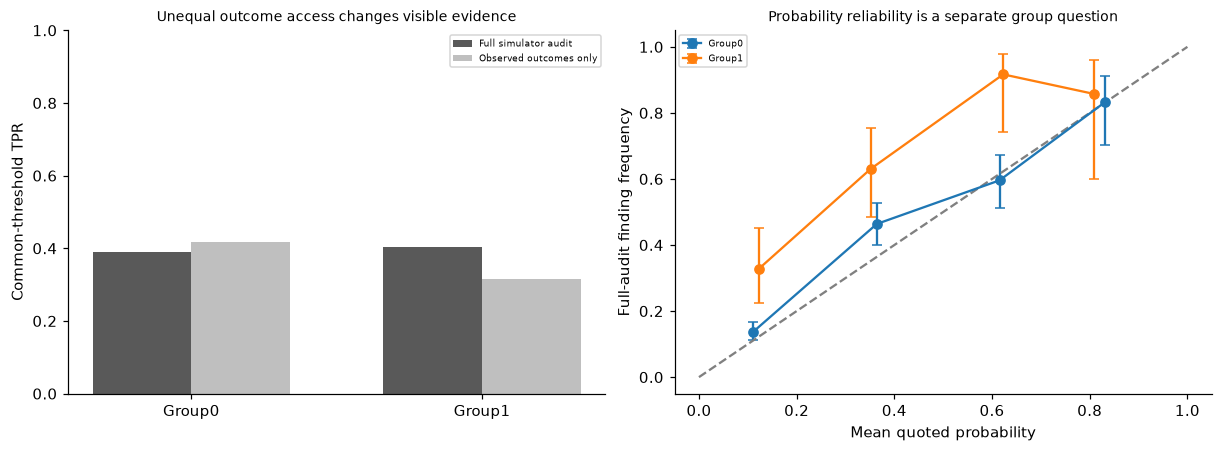

In [3]:
observed_audit={str(g):audit(decisions['Common 0.5'],(gf==g)&seen) for g in [0,1]};coverage={str(g):float(seen[gf==g].mean()) for g in [0,1]};calibration={}
for g in [0,1]:
    rows=[]
    for b in range(4):
        mask=(gf==g)&(pf>=b/4)&((pf<(b+1)/4) if b<3 else (pf<=1));n=int(mask.sum());rows.append({'n':n,'mean_probability':float(pf[mask].mean()) if n else None,'finding_frequency':float(yf[mask].mean()) if n else None,'Wilson95':wilson(int(yf[mask].sum()),n)})
    calibration[str(g)]=rows;assert sum(r['n'] for r in rows)==int(np.sum(gf==g))
assert all(row['n']>0 for row in observed_audit.values());RESULTS.update(final_observed_label_coverage=coverage,observed_label_only_group_audit=observed_audit,full_simulator_calibration_bins=calibration,complete_final_truth_is_privileged_audit=True);fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(2);axes[0].bar(xx-.17,[audits['Common 0.5'][str(g)]['TPR'] for g in [0,1]],.34,label='Full simulator audit',color='.35');axes[0].bar(xx+.17,[observed_audit[str(g)]['TPR'] for g in [0,1]],.34,label='Observed outcomes only',color='.75');axes[0].set(xticks=xx,xticklabels=['Group0','Group1'],ylabel='Common-threshold TPR',ylim=(0,1),title='Unequal outcome access changes visible evidence');axes[0].legend(fontsize=6)
for g in [0,1]:
    rows=[r for r in calibration[str(g)] if r['n']];x=np.array([r['mean_probability'] for r in rows]);y=np.array([r['finding_frequency'] for r in rows]);bounds=np.array([r['Wilson95'] for r in rows]);axes[1].errorbar(x,y,yerr=np.r_[(y-bounds[:,0])[None],(bounds[:,1]-y)[None]],fmt='o-',capsize=3,label=f'Group{g}')
axes[1].plot([0,1],[0,1],color='.5',linestyle='--');axes[1].set(xlabel='Mean quoted probability',ylabel='Full-audit finding frequency',title='Probability reliability is a separate group question');axes[1].legend(fontsize=6);plt.show()


In [4]:
summary={'example_id':'code_211','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual subgroup TPR FPR precision calibration and allocation assessment', 'Wilson frequency intervals and minority-group denominators', 'independent development group-threshold comparison', 'unequal outcome coverage contrasted with privileged simulator full audit'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual subgroup TPR FPR precision calibration and allocation assessment", "Wilson frequency intervals and minority-group denominators", "independent development group-threshold comparison", "unequal outcome coverage contrasted with privileged simulator full audit"], "elapsed_seconds": 0.336, "example_id": "code_211", "hardware": "Darwin arm64 CPU", "results": {"complete_final_truth_is_privileged_audit": true, "development_complete_audit_candidates": 600, "final_candidates": 1200, "final_observed_label_coverage": {"0": 0.6977186311787072, "1": 0.24324324324324326}, "full_simulator_calibration_bins": {"0": [{"Wilson95": [0.11225276875217668, 0.16604736216671181], "finding_frequency": 0.13694267515923567, "mean_probability": 0.11079816171202975, "n": 628}, {"Wilson95": [0.40116307619611696, 0.5276600433944401], "finding_frequency": 0.46382978723404256, "mean_probability": 0.3641223877760179, "n": 235}, {"Wilson95": [0.5132427445954546, 0.